# Implementaciones alternativas.

**Descripción**.

El problema de flujo y transporte reactivo de 2 especies en equilibrio con el yeso en 1D desarrollada en la notebook **1_GWF_DFC_WMA_Imp.ipynb** se puede implementar en un archivo `.py`. Esto se hace en el archivo **3_GWF_DFC_WMA_Imp.py**. También, se puede usar la API de MODFLOW para tomar la información del flujo directamente de memoria y usar esta información en otros procesos; esto último se hace en el archivo **4_GWF_API_DFC_Imp_WMA.py**. Finalmente, se usa GWT y la API para generar los coeficientes de la matriz del transporte conservativo y con esta información generar las matrices de las proporciones de mezcla, esto se hace en el archivo **5_GWF_GWT_API_WMA.py**. 
Todo lo anterior se describe en esta notebook.

<a href="https://github.com/luiggix/RTWMA">RTWMA</a> © 2024-2026 by <a href="https://www.geofisica.unam.mx">IGF-UNAM</a> is licensed under <a href="https://creativecommons.org/licenses/by-nc/4.0/">CC BY-NC 4.0</a><img src="https://mirrors.creativecommons.org/presskit/icons/cc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/by.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/nc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;">

# Ejecución en línea de comando.

En el archivo [**3_GWF_DFC_WMA_Imp.py**](3_GWF_DFC_WMA_Imp.py) se han implementado todos los pasos descritos en la notebook [**1_GWF_DFC_WMA_Imp.ipynb**](1_GWF_DFC_WMA_Imp.ipynb). La ejecución de esta implementación se realiza directamente en línea con el comando: 

* `python 3_GWF_DFC_WMA_Imp.py`

De igual manera se puede ejecutar en una celda como sigue:


Environment variables
―――――――――――――――――――――
     MF6EXE = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/mf6
     MF6DLL = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/libmf6.dll
RT_BINARIES = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin
   ROOT_DIR = C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\02_RT_WMA_gypsum_1D
―――――――――――――――――――――

Paths, filenames and more ...
―――――――――――――――――――――――――――――
                  mf6_exe = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/mf6
                  mf6_dll = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/libmf6.dll
          wma_working_dir = C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\02_RT_WMA_gypsum_1D\rt_workingDir
                 tr1d_exe = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin\TR_1D_oper.exe
                flow_name = flow
                  flow_ws = io_mf6/gwf_dfc_wma
              num_results = C:\Users\luiggi\Docum

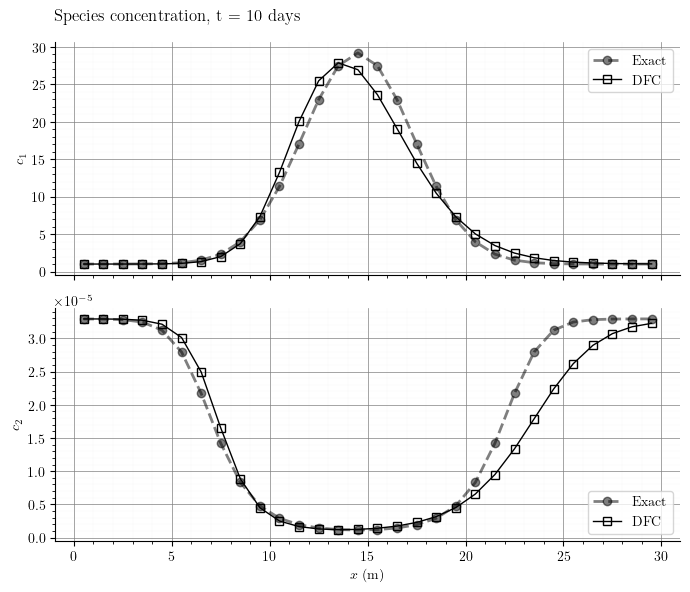

In [1]:
%run 3_GWF_DFC_WMA_Imp.py

# Optimización usando GWF + API.

MODFLOW ofrece una API a través de la cual se puede acceder al contenido de las variables en memoria de una simulación. Usando esta API se puede ejecutar el modelo de flujo y en tiempo de ejecución recuperar los resultados del flujo (`head` y `q`) para posteriormente usarlos en el cálculo del transporte reactivo. La figura 1 muestra el flujo de información de esta implementación.

<figure>
  <img src="../figures/gwf_api_dfc_wma.svg" width=700px alt="dominio de estudio y condiciones" />
  <figcaption>

Figura 1. El flujo se resuelve usando GWF a través de la API de MODFLOW, los datos que requiere el modelo se proporcionan en diccionarios de Python (`dis`, `tdis`, `phys`, entre otros). GWF genera los resultados del flujo en arreglos que se pueden recuperar usando la API. Esta información es utilizada por DFC para generar los coeficientes de la discretización del modelo de transporte, dichos coeficientes se generan en memoria, posteriormente se calculan las proporciones de mezcla ($\lambda$'s) y se guardan en archivos (`.dat`); esto se implementa en la función `mixingRatios_dfc()` que se encuentra en el archivo [**lambdas.py**](gypsum/lambdas.py) que está en la carpeta **gypsum/**. Finalmente, el ejecutable **TR_1D_oper.exe** realiza los cálculos de transporte reactivo usando las proporciones de mezcla y guarda los resultados en archivos (`.out`). En esta última etapa, se realizan todos los pasos de tiempo del problema de transporte reactivo para un flujo estacionario.

</figcaption>
</figure>

La implementación de esta optimización se puede ver en el archivo [**4_GWF_API_DFC_Imp_WMA.py**](4_GWF_API_DFC_Imp_WMA.py). Se puede ejecutar en línea con el comando:

* `python 4_GWF_API_DFC_Imp_WMA.py`

y también en una celda como sigue:


Environment variables
―――――――――――――――――――――
     MF6EXE = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/mf6
     MF6DLL = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/libmf6.dll
RT_BINARIES = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin
   ROOT_DIR = C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\02_RT_WMA_gypsum_1D
―――――――――――――――――――――

Paths, filenames and more ...
―――――――――――――――――――――――――――――
                  mf6_exe = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/mf6
                  mf6_dll = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/libmf6.dll
          wma_working_dir = C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\02_RT_WMA_gypsum_1D\rt_workingDir
                 tr1d_exe = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin\TR_1D_oper.exe
                flow_name = flow
                  flow_ws = io_mf6/gwf_api_dfc_wma
              num_results = C:\Users\luiggi\D

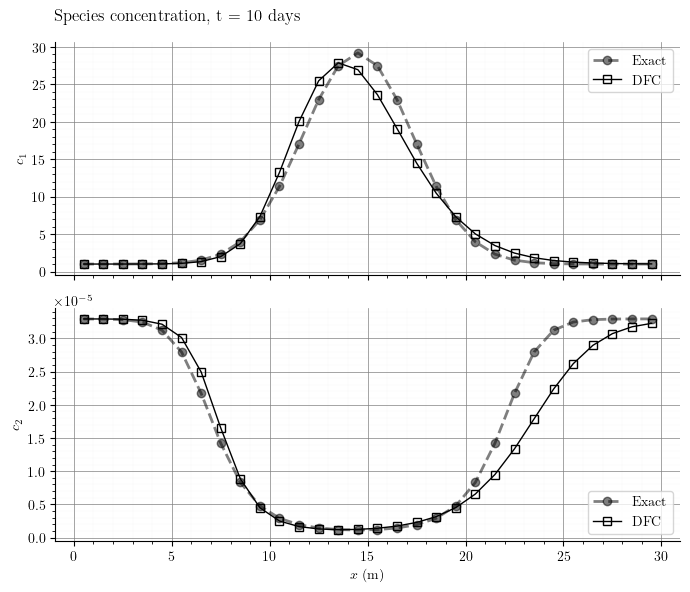

In [2]:
%run 4_GWF_API_DFC_Imp_WMA.py

# Optimización usando GWT + API.

En este caso, se generan los coeficientes de la matriz del transporte conservativo usando GWT y posteriormente se utiliza la API para extraer estos coeficientes del sistema lineal directamente de memoria. Los coeficientes son usados para generar las matrices de las proporciones de mezcla. La carpeta **gypsum/** contiene módulos separados para la solución del flujo ([**gwf.py**](gypsum/gwf.py)), la solución del transporte conservativo (un solo paso para generar las matrices) ([**gwt.py**](gypsum/gwt.py)); la extracción de la información del sistema lineal con la API ([**gwt_api.py**](gypsum/gwt_api.py)), la construcción de las matrices de las proporciones de mezcla ([**lambdas.py**](gypsum/lambdas.py)), el cálculo del transporte reactivo ([**wma.py**](gypsum/wma.py)) y el análisis y visualización de resultados ([**vis.py**](gypsum/vis.py)).

La figura 2 muestra el flujo de información de esta implementación.

<figure>
  <img src="../figures/gwf_gwt_api_wma.svg" width=700px alt="dominio de estudio y condiciones" />
  <figcaption>

Figura 2. Solución del transporte reactivo usando GWF, GWT+API, Lambdas y Remix. Nótese que GWF almacena los resultados en archivos que después son recuperados por GWT.
</figcaption>
</figure>

La implementación de esta optimización se puede ver en el archivo [**5_GWF_GWT_API_WMA.py**](5_GWF_GWT_API_WMA.py). Se puede ejecutar en línea con el comando:

* `python 5_GWF_GWT_API_WMA.py`

y también en una celda como sigue:


Environment variables
―――――――――――――――――――――
     MF6EXE = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/mf6
     MF6DLL = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/libmf6.dll
RT_BINARIES = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin
   ROOT_DIR = C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\02_RT_WMA_gypsum_1D
―――――――――――――――――――――

Paths, filenames and more ...
―――――――――――――――――――――――――――――
                  mf6_exe = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/mf6
                  mf6_dll = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/libmf6.dll
          wma_working_dir = C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\02_RT_WMA_gypsum_1D\rt_workingDir
                 tr1d_exe = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin\TR_1D_oper.exe
                flow_name = flow
                  flow_ws = io_mf6/gwf_gwt_api_wma/gwf
                tran_name = transport
   

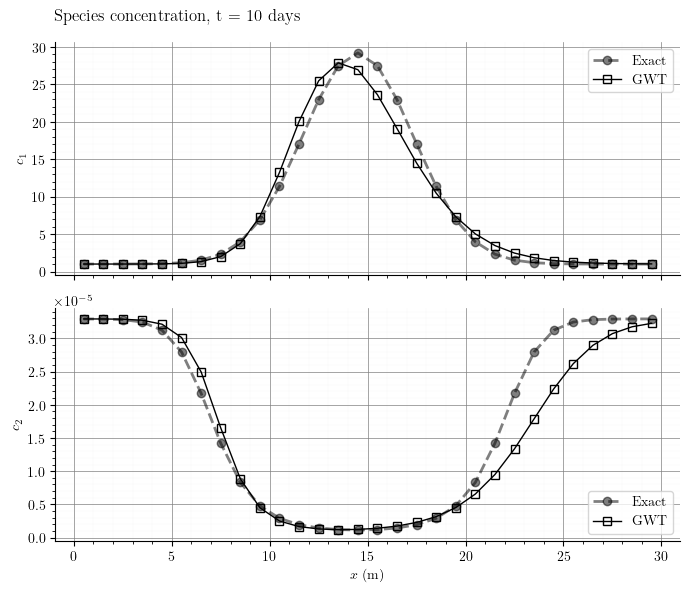

In [3]:
%run 5_GWF_GWT_API_WMA.py

# Optimización usando GWF-GWT exchange y la API.

En esta implementación se construye un modelo de tipo GWF-GWT con intercambio para resolver el flujo y obtener las matrices del modelo de transporte. En este caso el flujo de información es como se muestra en la figura 3.

<figure>
  <img src="../figures/mf6_flujo_transporte_exch.svg" width=450px alt="dominio de estudio y condiciones" />
  <figcaption>Figura 3. En una simulación de MODFLOW 6 de flujo y transporte, es posible agregar un intercambio para compartir información entre ambos modelos. Al final de la simulación se generan archivos con los resultados del flujo y del transporte. Véase (Langevin et al. 2023). </figcaption>
</figure>

Este tipo de modelo nos permite compartir prácticamente toda la información a través de la memoria; con excepción de la parte final en donde se realiza el cálculo del transporte reactivo. La figura 4 muestra el flujo de información de esta implementación. 

<figure>
  <img src="../figures/gwf_gwt_exch_api_wma.svg" width=700px alt="dominio de estudio y condiciones" />
  <figcaption>

Figura 4. Solución del transporte reactivo usando GWF-GWT exchange, API, Lambdas y Remix.
</figcaption>
</figure>

La carpeta **gypsum/** contiene módulos separados con la implementación del flujo ([**gwf_exch.py**](gypsum/gwf_exch.py)), del transporte conservativo (gypsum/gwt_exch.py), la extracción de la información del sistema lineal del transporte con la API ([**gwf_gwt_exch_api.py**](gypsum/gwf_gwt_exch_api.py)), la construcción de las matrices de las proporciones de mezcla (función `mixingRatios_gwt()` en el archivo [**lambdas.py**](gypsum/lambdas.py)), el cálculo del transporte reactivo ([**wma.py**](gypsum/wma.py)) y el análisis y visualización de resultados ([**vis.py**](gypsum/vis.py)).

La implementación de esta optimización se puede ver en el archivo [**6_GWF_GWT_EXCH_API_WMA.py**](6_GWF_GWT_EXCH_API_WMA.py). Se puede ejecutar en línea con el comando:

* `python 6_GWF_GWT_EXCH_API_WMA.py`

y también en una celda como sigue:


Environment variables
―――――――――――――――――――――
     MF6EXE = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/mf6
     MF6DLL = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/libmf6.dll
RT_BINARIES = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin
   ROOT_DIR = C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\02_RT_WMA_gypsum_1D
―――――――――――――――――――――

Paths, filenames and more ...
―――――――――――――――――――――――――――――
                  mf6_exe = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/mf6
                  mf6_dll = C:/Users/luiggi/Documents/GitSites/mf6_tutorial/mf6/windows/libmf6.dll
          wma_working_dir = C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\02_RT_WMA_gypsum_1D\rt_workingDir
                 tr1d_exe = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin\TR_1D_oper.exe
                 sim_name = flow_trans
                   sim_ws = io_mf6/gwf_gwt_exch_api_wma
                flow_name = flow
 

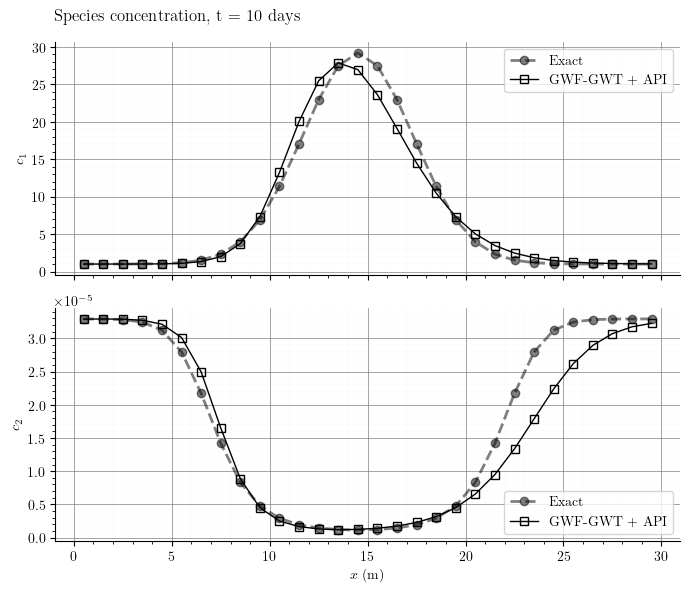

In [4]:
%run 6_GWF_GWT_EXCH_API_WMA.py